In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Paleta del curso
INDIGO, PURPURA, CORAL, TINTA = '#4F46E5', '#7E22CE', '#F43F5E', '#111827'

plt.rcParams.update({
    'figure.figsize': (7, 4.2),
    'axes.grid': True, 
    'grid.alpha': 0.3,
    'axes.spines.top': False,
    'axes.spines.right': False
})

In [2]:
rng = np.random.default_rng(42)  # Semilla: resultados reproducibles
m = 60                           # Número de muestras

horas = rng.uniform(0, 10, m)
nota = 30 + 5 * horas + rng.normal(0, 5, m)

print('Primeras 5 muestras:')
for h, n in zip(horas[:5], nota[:5]):
    print(f'horas = {h:5.2f}  nota = {n:6.2f}')

Primeras 5 muestras:
horas =  7.74  nota =  64.37
horas =  4.39  nota =  56.79
horas =  8.59  nota =  64.52
horas =  6.97  nota =  63.19
horas =  0.94  nota =  35.52


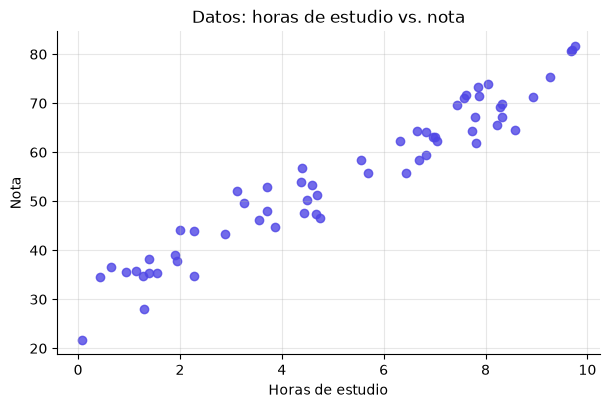

In [3]:
plt.scatter(horas, nota, color=INDIGO, alpha=0.8)
plt.xlabel('Horas de estudio')
plt.ylabel('Nota')
plt.title('Datos: horas de estudio vs. nota')
plt.show()

In [4]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

X = horas.reshape(-1, 1)  # Matriz 2D: (muestras, características)
y = nota                  # El objetivo es un vector 1D

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0
)

print('Entrenamiento:', X_train.shape, 'Prueba:', X_test.shape)

Entrenamiento: (48, 1) Prueba: (12, 1)


In [5]:
modelo = LinearRegression()
modelo.fit(X_train, y_train)

w_sk = modelo.coef_[0]       # Coeficiente (pendiente)
b_sk = modelo.intercept_     # Intercepto

print(f'Pendiente w = {w_sk:.4f} (valor real: 5)')
print(f'Intercepto b = {b_sk:.4f} (valor real: 30)')
print(f'\nModelo aprendido: nota = {b_sk:.2f} + {w_sk:.2f} * horas')

Pendiente w = 5.0675 (valor real: 5)
Intercepto b = 28.5394 (valor real: 30)

Modelo aprendido: nota = 28.54 + 5.07 * horas


In [6]:
y_pred = modelo.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f'MAE (error absoluto medio)     = {mae:.3f} puntos')
print(f'MSE (error cuadrático medio)   = {mse:.3f}')
print(f'RMSE (raíz del MSE)            = {rmse:.3f} puntos')
print(f'R2 (coef. de determinación)    = {r2:.3f}')

MAE (error absoluto medio)     = 2.781 puntos
MSE (error cuadrático medio)   = 12.188
RMSE (raíz del MSE)            = 3.491 puntos
R2 (coef. de determinación)    = 0.946


In [7]:
nuevos = np.array([[2], [5], [8]])

for h, p in zip(nuevos.ravel(), modelo.predict(nuevos)):
    print(f'Con {h} horas de estudio se predice una nota de {p:.1f}')

Con 2 horas de estudio se predice una nota de 38.7
Con 5 horas de estudio se predice una nota de 53.9
Con 8 horas de estudio se predice una nota de 69.1


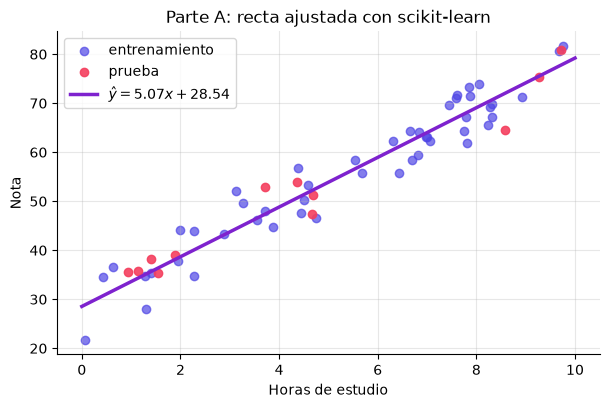

In [8]:
xs = np.linspace(0, 10, 100).reshape(-1, 1)

plt.scatter(X_train, y_train, color=INDIGO, alpha=0.7, label='entrenamiento')
plt.scatter(X_test, y_test, color=CORAL, alpha=0.9, label='prueba')
plt.plot(xs, modelo.predict(xs), color=PURPURA, lw=2.5,
         label=f'$\\hat{{y}} = {w_sk:.2f}x + {b_sk:.2f}$')

plt.xlabel('Horas de estudio')
plt.ylabel('Nota')
plt.title('Parte A: recta ajustada con scikit-learn')
plt.legend()
plt.show()

In [9]:
def costo(w, b, x, y):
    y_pred = w * x + b
    return np.mean((y_pred - y) ** 2) / 2

# Convertimos a vectores 1D para simplificar cálculos iterativos
x_train, x_test = X_train.ravel(), X_test.ravel()

print(f'J(0, 0) = {costo(0, 0, x_train, y_train):8.2f} <- recta en 0')
print(f'J(5, 30) = {costo(5, 30, x_train, y_train):8.2f} <- relación real')

J(0, 0) =  1667.25 <- recta en 0
J(5, 30) =     7.88 <- relación real


In [10]:
def gradientes(w, b, x, y):
    y_pred = w * x + b
    error = y_pred - y
    dw = np.mean(error * x)
    db = np.mean(error)
    return dw, db

dw, db = gradientes(0, 0, x_train, y_train)
print(f'En (w, b) = (0, 0): ∂J/∂w = {dw:.2f}, ∂J/∂b = {db:.2f}')

En (w, b) = (0, 0): ∂J/∂w = -339.86, ∂J/∂b = -55.98


In [11]:
def descenso_gradiente(x, y, alpha=0.01, iteraciones=10_000):
    w, b = 0.0, 0.0
    historial = []
    
    for i in range(iteraciones):
        dw, db = gradientes(w, b, x, y)
        w = w - alpha * dw
        b = b - alpha * db
        
        historial.append(costo(w, b, x, y))
        
        if i in (0, 10, 100, 1000, iteraciones - 1):
            print(f'iter {i:>5}: w = {w:7.4f}, b = {b:8.4f}, J = {historial[-1]:9.4f}')
            
    return w, b, historial

w_gd, b_gd, historial = descenso_gradiente(x_train, y_train, alpha=0.01, iteraciones=10_000)

iter     0: w =  3.3986, b =   0.5598, J =  702.4903
iter    10: w =  8.9765, b =   1.9226, J =   77.3678
iter   100: w =  8.3954, b =   6.1889, J =   56.6861
iter  1000: w =  5.6493, b =  24.6320, J =    8.7716
iter  9999: w =  5.0675, b =  28.5394, J =    7.2610


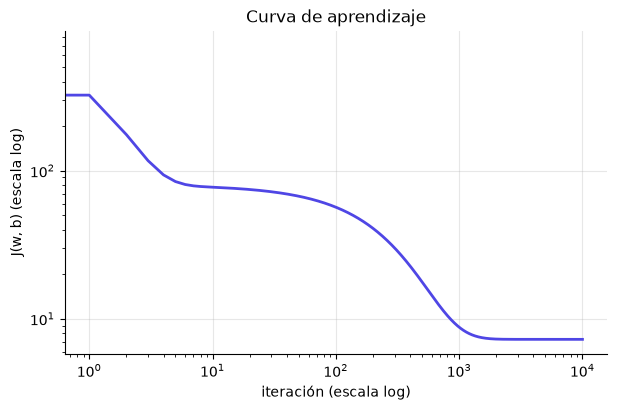

In [12]:
plt.plot(historial, color=INDIGO, lw=2)
plt.xscale('log')
plt.yscale('log')
plt.xlabel('iteración (escala log)')
plt.ylabel('J(w, b) (escala log)')
plt.title('Curva de aprendizaje')
plt.show()

In [13]:
y_pred_gd = w_gd * x_test + b_gd

mae_gd = np.mean(np.abs(y_test - y_pred_gd))
rmse_gd = np.sqrt(np.mean((y_test - y_pred_gd) ** 2))
ss_res = np.sum((y_test - y_pred_gd) ** 2)
ss_tot = np.sum((y_test - y_test.mean()) ** 2)
r2_gd = 1 - (ss_res / ss_tot)

print(f'MAE  = {mae_gd:.3f} puntos')
print(f'RMSE = {rmse_gd:.3f} puntos')
print(f'R2   = {r2_gd:.3f}')

MAE  = 2.781 puntos
RMSE = 3.491 puntos
R2   = 0.946


In [14]:
print(f'{"":22}{"w":>10}{"b":>10}')
print(f'{"Valor real":22}{5.0:>10.4f}{30.0:>10.4f}')
print(f'{"scikit-learn":22}{w_sk:>10.4f}{b_sk:>10.4f}')
print(f'{"Descenso de gradiente":22}{w_gd:>10.4f}{b_gd:>10.4f}')
print(f'\nDiferencia |w_sk - w_gd| = {abs(w_sk - w_gd):.2e}')
print(f'Diferencia |b_sk - b_gd| = {abs(b_sk - b_gd):.2e}')

                               w         b
Valor real                5.0000   30.0000
scikit-learn              5.0675   28.5394
Descenso de gradiente     5.0675   28.5394

Diferencia |w_sk - w_gd| = 1.55e-08
Diferencia |b_sk - b_gd| = 1.04e-07


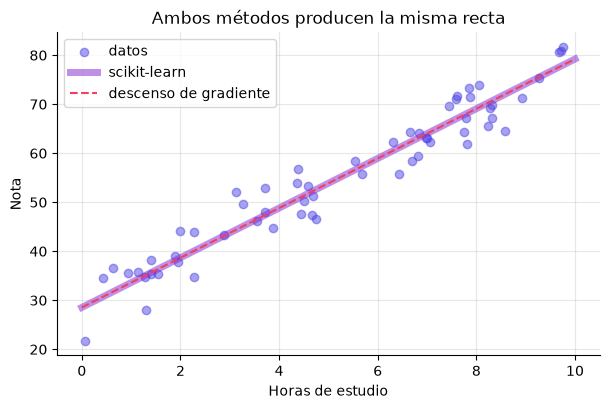

In [15]:
plt.scatter(horas, nota, color=INDIGO, alpha=0.5, label='datos')
plt.plot(xs, modelo.predict(xs), color=PURPURA, lw=5, alpha=0.5, label='scikit-learn')
plt.plot(xs, w_gd * xs + b_gd, color=CORAL, lw=1.5, ls='--', label='descenso de gradiente')

plt.xlabel('Horas de estudio')
plt.ylabel('Nota')
plt.title('Ambos métodos producen la misma recta')
plt.legend()
plt.show()